<a href="https://colab.research.google.com/github/PriyaRai922/Form1/blob/main/Blinkit_Analysis_in_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**DATA ANALYSIS PYTHON PROJECT -- BLINKIT ANALYSIS**

**Import libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# from matplotlib.pyplot import Figure

**Import Raw data**

In [ ]:
df = pd.read_csv("/content/blinkit_data.csv")

**Samples data**

In [ ]:
df.head(10)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0
5,low fat,FDS52,Frozen Foods,2020,OUT017,Tier 2,Small,Supermarket Type1,0.005505,8.89,102.4016,5.0
6,Low Fat,NCU05,Health and Hygiene,2011,OUT010,Tier 3,Small,Grocery Store,0.098312,11.80,81.4618,5.0
7,Low Fat,NCD30,Household,2015,OUT045,Tier 2,Small,Supermarket Type1,0.026904,19.70,96.0726,5.0
8,Low Fat,FDW20,Fruits and Vegetables,2000,OUT013,Tier 3,High,Supermarket Type1,0.024129,20.75,124.1730,5.0
9,Low Fat,FDX25,Canned,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.101562,NaN,181.9292,5.0


In [ ]:
df.tail(10)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
8513,Regular,DRY23,Soft Drinks,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.108568,NaN,42.9112,4.0
8514,low fat,FDA11,Baking Goods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.043029,NaN,94.7436,4.0
8515,low fat,FDK38,Canned,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.053032,NaN,149.1734,4.0
8516,low fat,FDO38,Canned,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.072486,NaN,78.9986,4.0
8517,low fat,FDG32,Fruits and Vegetables,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.175143,NaN,222.3772,4.0
8518,low fat,NCT53,Health and Hygiene,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,164.5526,4.0
8519,low fat,FDN09,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.034706,NaN,241.6828,4.0
8520,low fat,DRE13,Soft Drinks,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.027571,NaN,86.6198,4.0
8521,reg,FDT50,Dairy,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.107715,NaN,97.8752,4.0
8522,reg,FDM58,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,112.2544,4.0


**Size of Data**

In [ ]:
print("Size of data:",df.shape)

Size of data: (8523, 12)


**Field info**

In [ ]:
df.columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='object')

**Data types**

In [ ]:
df.dtypes

,0
Item Fat Content,object
Item Identifier,object
Item Type,object
Outlet Establishment Year,int64
Outlet Identifier,object
Outlet Location Type,object
Outlet Size,object
Outlet Type,object
Item Visibility,float64
Item Weight,float64


**Data Cleaning**

In [ ]:
print(df['Item Fat Content'].unique())

['Regular' 'Low Fat' 'low fat' 'LF' 'reg']


In [ ]:
df['Item Fat Content'] = df['Item Fat Content'].replace({'LF': 'Low Fat',
                                                         'low fat':'Low Fat',
                                                         'reg':'Regular'})

In [ ]:
print(df['Item Fat Content'].unique())

['Regular' 'Low Fat']


**Business Requirements**

**KPI's Requirement**

In [ ]:
#total Sales
total_sales = df['Sales'].sum()

#Avgerage Sales
avg_sales = df['Sales'].mean()

#no of item solds
no_of_item_solds =df['Sales'].count()

#average ratings
avg_ratings = df['Rating'].mean()

print(f"Total Sales:${total_sales:,.0f}")
print(f"Average Sales:${avg_sales:,.0f}")
print(f"No of item solds:${no_of_item_solds:,.0f}")
print(f"Average Ratings:${avg_ratings:,.0f}")


Total Sales:$1,201,681
Average Sales:$141
No of item solds:$8,523
Average Ratings:$4


***Charts Requirement***

**Total Sales by Fat Content**

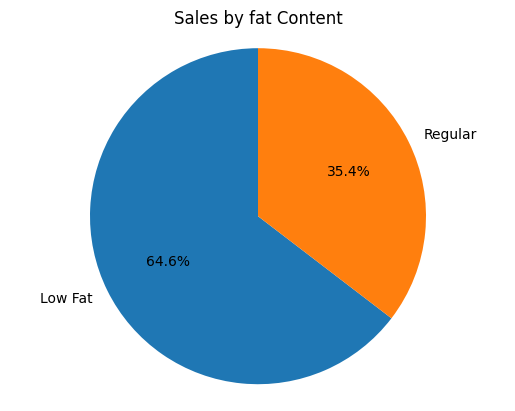

In [ ]:
sales_by_fat = df.groupby('Item Fat Content')['Sales'].sum()

sales_by_fat = sales_by_fat.astype(float)

plt.pie(
    sales_by_fat,
    labels=sales_by_fat.index,
    autopct='%.1f%%',
    startangle=90
)

plt.title('Sales by fat Content')
plt.axis('equal')
plt.show()

**Total Sales by Item Type**

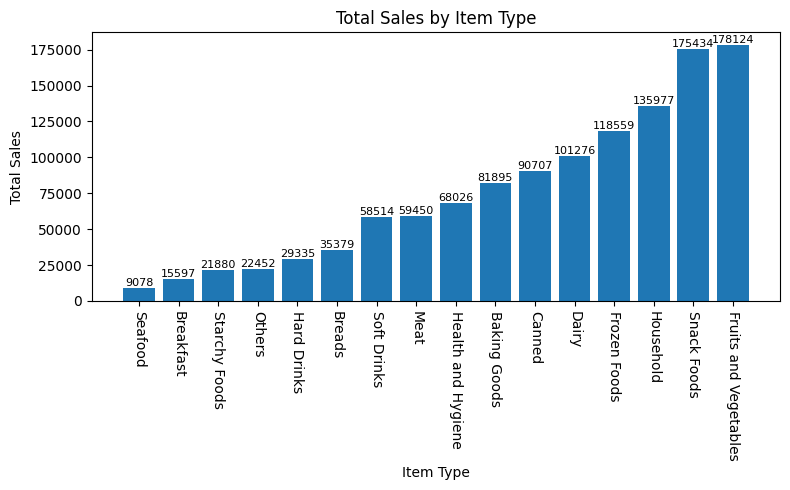

In [ ]:
sales_by_types = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=True)

plt.figure(figsize=(8, 5))
bars = plt.bar(sales_by_types.index, sales_by_types.values)
plt.xlabel('Item Type')
plt.ylabel('Total Sales')
plt.title('Total Sales by Item Type')
plt.xticks(rotation=-90)

for bar in bars:
  plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{bar.get_height():.0f}', ha='center', va='bottom',fontsize=8)

plt.tight_layout()
plt.show()

**Fat content by Outlet for Total Sales**

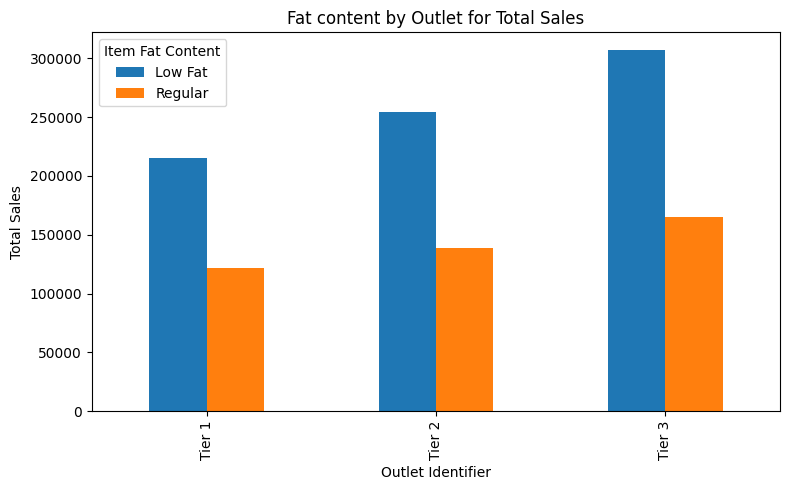

In [ ]:
grouped = df.groupby(['Outlet Location Type','Item Fat Content'])['Sales'].sum().unstack()

grouped = grouped[['Low Fat','Regular']]

ax =grouped.plot(kind='bar',figsize=(8,5),title="Fat content by Outlet for Total Sales")
ax.set_xlabel("Outlet Identifier")
ax.set_ylabel("Total Sales")
plt.legend(title="Item Fat Content")
plt.tight_layout()
plt.show()


**Total Sales by Outlet Establishment**

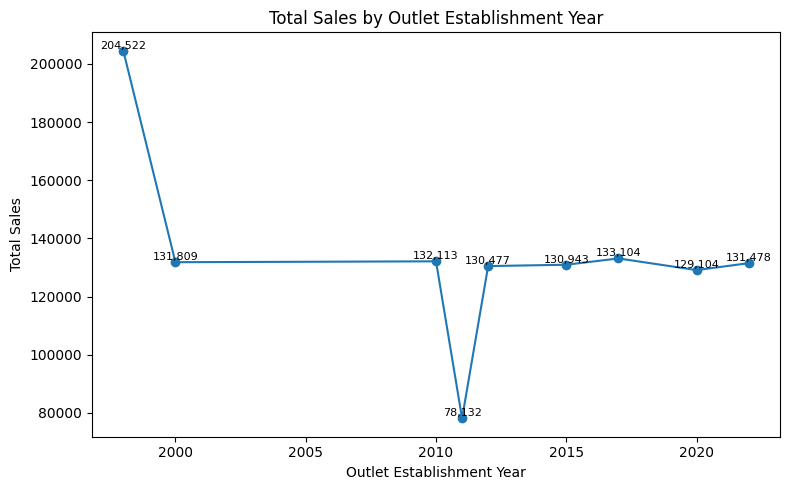

In [ ]:
sales_by_year = df.groupby('Outlet Establishment Year')['Sales'].sum().sort_index()

plt.figure(figsize=(8, 5))
plt.plot(sales_by_year.index, sales_by_year.values, marker='o', linestyle='-')

plt.xlabel('Outlet Establishment Year')
plt.ylabel('Total Sales')
plt.title('Total Sales by Outlet Establishment Year')

for x,y in zip(sales_by_year.index, sales_by_year.values):
  plt.text(x,y,f'{y:,.0f}',ha='center',va='bottom',fontsize=8)




plt.tight_layout()
plt.show()

**Sales by Outlet Size**

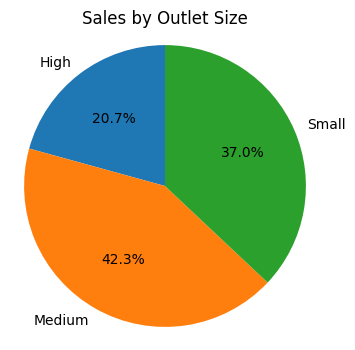

In [ ]:
sales_by_size =df.groupby('Outlet Size')['Sales'].sum()

plt.figure(figsize=(4,4))
plt.pie(sales_by_size,labels=sales_by_size.index,autopct='%.1f%%',startangle=90)
plt.title('Sales by Outlet Size')
plt.axis('equal')
plt.show()

**Sales by Outlets Location**

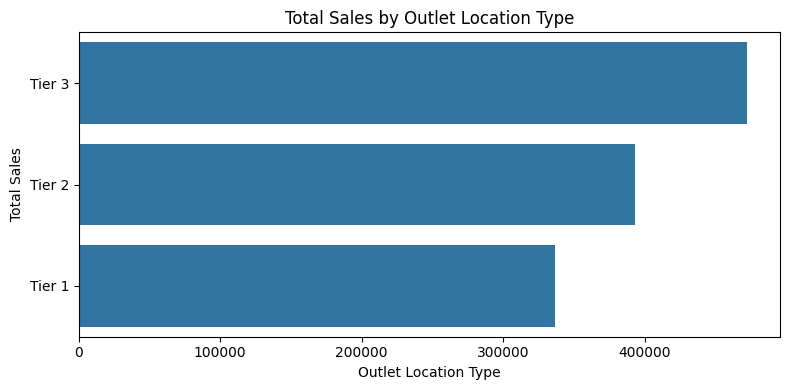

In [ ]:

sales_by_location = df.groupby('Outlet Location Type')['Sales'].sum().reset_index()
sales_by_location = sales_by_location.sort_values('Sales',ascending=False)

plt.figure(figsize=(8,4))
ax =sns.barplot(x='Sales' , y='Outlet Location Type',data =sales_by_location)


plt.xlabel('Outlet Location Type')
plt.ylabel('Total Sales')
plt.title('Total Sales by Outlet Location Type')

plt.tight_layout()
plt.show()